# Dynamic Games in Trading — Dataset Builder
**Frequency-Dependent Payoffs and Bounded Capital Flows**

Run all cells top to bottom. It creates:

```
dataset/
  alcohol/      alcohol_normal.csv, alcohol_situations.csv
  automobile/   automobile_normal.csv, automobile_situations.csv
  banking/      banking_normal.csv, banking_situations.csv
  technology/   technology_normal.csv, technology_situations.csv
```

Only two CSVs per industry. `*_situations.csv` holds every situation stacked; filter by the `Situation` column
(financial_crisis, covid_crash_panic, covid_recovery, bear_market_2022, bull_run_2023_2024, sideways_choppy).

**What is built for the problem statement**
- 20 years of daily data per company (auto-computed from today), with OHLC fully split+dividend adjusted so prices are internally consistent.
- Payoff / impact inputs: `DollarVolume`, `ADV20` (20-day average dollar volume, for capacity and bounded capital flows), `HL_Range` (spread proxy), `Vol20`.
- Market context: home-market benchmark return, daily risk-free rate, `Excess_Return`.
- Regimes: calendar situations (2008 crisis, COVID crash, COVID recovery, 2022 bear, 2023-24 bull) plus a **rule-based sideways/choppy** situation per company and a `Regime_Rule` label on every day.
- Cleaning: bad-tick removal, zero-volume rows dropped, OHLC fixed, every action logged.
- All features are computed on the **full** history first and then sliced into situations, so rolling windows have no warm-up gaps inside a situation file.

In [1]:
%pip install -q yfinance pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, time, shutil, warnings
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
YEARS = 20
END_DATE = pd.Timestamp.today().normalize()
START_DATE = END_DATE - pd.DateOffset(years=YEARS)
DATASET_DIR = "dataset"

# name -> Yahoo ticker, or a list of tickers tried in order (fallbacks)
COMPANIES = {
    "alcohol": {
        "Diageo": "DEO",
        "AB_InBev": "BUD",
        "Pernod_Ricard": "RI.PA",
        "United_Spirits": ["UNITDSPR.NS", "MCDOWELL-N.NS"],
        "Molson_Coors": "TAP",
        "Constellation_Brands": "STZ",
    },
    "technology": {
        "Apple": "AAPL",
        "Intel": "INTC",
        "Samsung": "005930.KS",
        "Sony": "SONY",
        "Microsoft": "MSFT",
        "Nvidia": "NVDA",
    },
    "automobile": {
        "Tesla": "TSLA",
        "Toyota": "TM",
        "Tata_Motors": ["TATAMOTORS.NS", "TMPV.NS"],
        "Ford": "F",
        "Honda": "HMC",
        "Maruti_Suzuki": "MARUTI.NS",
    },
    "banking": {
        "JPMorgan": "JPM",
        "Bank_of_America": "BAC",
        "HDFC_Bank": "HDFCBANK.NS",
        "ICICI_Bank": "ICICIBANK.NS",
        "Citigroup": "C",
        "Wells_Fargo": "WFC",
    },
}

# home-market benchmark by ticker suffix (default = S&P 500)
BENCHMARKS = {"^GSPC": "SP500", "^NSEI": "Nifty50", "^KS11": "KOSPI", "^FCHI": "CAC40", "^VIX": "VIX"}
SUFFIX_TO_INDEX = {".NS": "^NSEI", ".KS": "^KS11", ".PA": "^FCHI"}
SUFFIX_TO_CCY = {".NS": "INR", ".KS": "KRW", ".PA": "EUR", ".AS": "EUR"}
RF_TICKER = "^IRX"   # 13-week US T-bill yield (% annualised)

# calendar situations (start, end) — applied to every company that has data in the window
SITUATIONS = {
    "financial_crisis":   ("2008-09-01", "2009-03-31"),
    "covid_crash_panic":  ("2020-02-19", "2020-03-23"),
    "covid_recovery":     ("2020-03-24", "2020-06-30"),
    "bear_market_2022":   ("2022-01-03", "2022-10-14"),
    "bull_run_2023_2024": ("2023-01-01", "2024-12-31"),
}
MIN_SIDEWAYS_RUN = 40      # trading days a sideways stretch must last to count as a situation
SPIKE_THRESHOLD = 0.35     # |daily return| above this AND reversed next day => bad tick

print("History window:", START_DATE.date(), "->", END_DATE.date())

History window: 2006-10-11 -> 2026-10-11


In [3]:
# ---------------- HELPERS ----------------
def ccy_of(ticker):
    for suf, c in SUFFIX_TO_CCY.items():
        if ticker.endswith(suf):
            return c
    return "USD"

def index_of(ticker):
    for suf, idx in SUFFIX_TO_INDEX.items():
        if ticker.endswith(suf):
            return idx
    return "^GSPC"

def _flatten(df):
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    return df.loc[:, ~df.columns.duplicated()]

def download_one(tickers, retries=3):
    tickers = [tickers] if isinstance(tickers, str) else list(tickers)
    for tk in tickers:
        for attempt in range(retries):
            try:
                df = yf.download(tk, start=START_DATE.strftime("%Y-%m-%d"),
                                 end=(END_DATE + pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
                                 auto_adjust=False, progress=False)
                df = _flatten(df)
                if df is not None and not df.empty and {"Close", "Adj Close"} <= set(df.columns):
                    df = df.reset_index()
                    df = df.rename(columns={df.columns[0]: "Date"})
                    return tk, df
                break                      # empty result -> try next fallback ticker
            except Exception as e:
                time.sleep(2 * (attempt + 1))
    return None, None

def clean_prices(df):
    log = {}
    d = df.copy()
    d["Date"] = pd.to_datetime(d["Date"]).dt.tz_localize(None).dt.normalize()
    d = d[["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"]]
    d = d.dropna(subset=["Close", "Adj Close"]).drop_duplicates("Date").sort_values("Date")
    d = d[(d[["Open", "High", "Low", "Close", "Adj Close"]] > 0).all(axis=1)]

    # rows with zero volume are placeholders (holidays / halted days)
    log["zero_volume_dropped"] = int((d["Volume"].fillna(0) == 0).sum())
    d = d[d["Volume"].fillna(0) > 0]

    # make OHLC consistent with Adj Close (split + dividend adjusted)
    f = d["Adj Close"] / d["Close"]
    d["Raw_Close"] = d["Close"]
    for c in ["Open", "High", "Low"]:
        d[c] = d[c] * f
    d["Close"] = d["Adj Close"]

    hi = d[["Open", "High", "Low", "Close"]].max(axis=1)
    lo = d[["Open", "High", "Low", "Close"]].min(axis=1)
    log["ohlc_fixed"] = int(((d["High"] < hi - 1e-9) | (d["Low"] > lo + 1e-9)).sum())
    d["High"], d["Low"] = hi, lo

    # bad-tick removal: a huge move that reverses the very next day
    spikes = 0
    for _ in range(5):
        r = d["Adj Close"].pct_change()
        nxt = r.shift(-1)
        s = (r.abs() > SPIKE_THRESHOLD) & (nxt.abs() > SPIKE_THRESHOLD) & (((1 + r) * (1 + nxt) - 1).abs() < 0.10)
        if not s.any():
            break
        spikes += int(s.sum())
        d = d[~s]
    log["bad_ticks_removed"] = spikes
    r = d["Adj Close"].pct_change()
    log["big_moves_kept_(>30%)"] = int((r.abs() > 0.30).sum())
    return d.reset_index(drop=True), log

def add_features(d):
    d = d.sort_values("Date").reset_index(drop=True)
    d["Return"] = d["Adj Close"].pct_change()
    d["LogReturn"] = np.log1p(d["Return"])
    d["DollarVolume"] = d["Raw_Close"] * d["Volume"]
    d["ADV20"] = d["DollarVolume"].rolling(20, min_periods=20).mean()
    d["HL_Range"] = (d["High"] - d["Low"]) / d["Close"]
    d["Vol20"] = d["Return"].rolling(20, min_periods=20).std() * np.sqrt(252)
    d["Ret60"] = d["Close"].pct_change(60)
    d["Drawdown"] = d["Close"] / d["Close"].rolling(252, min_periods=60).max() - 1
    d["SMA200"] = d["Close"].rolling(200, min_periods=100).mean()
    med_vol = d["Vol20"].median()
    bear = d["Drawdown"] <= -0.20
    side = (d["Ret60"].abs() < 0.05) & (d["Vol20"] < med_vol)
    bull = (d["Close"] > d["SMA200"]) & (d["Ret60"] > 0.05)
    d["Regime_Rule"] = np.select([bear, side, bull], ["bear", "sideways", "bull"], "neutral")
    return d.iloc[1:].reset_index(drop=True)      # first row has no return

def sideways_frame(df, min_run=MIN_SIDEWAYS_RUN):
    out = []
    for tk, g in df.groupby("Ticker"):
        g = g.sort_values("Date")
        s = g["Regime_Rule"].eq("sideways")
        grp = (s != s.shift()).cumsum()
        size = s.groupby(grp).transform("size")
        keep = s & (size >= min_run)
        k = g[keep].copy()
        if k.empty:
            continue
        gk = grp[keep]
        k["Situation"] = "sideways_choppy"
        k["Situation_Start"] = k.groupby(gk)["Date"].transform("min")
        k["Situation_End"] = k.groupby(gk)["Date"].transform("max")
        out.append(k)
    return pd.concat(out) if out else df.iloc[0:0].assign(Situation=[], Situation_Start=[], Situation_End=[])

COLS = ["Date", "Ticker", "Company", "Industry", "Currency", "Open", "High", "Low", "Close", "Adj Close",
        "Raw_Close", "Volume", "Return", "LogReturn", "DollarVolume", "ADV20", "HL_Range", "Vol20", "Ret60",
        "Drawdown", "SMA200", "Regime_Rule", "Benchmark", "Benchmark_Return", "RF_Daily", "Excess_Return"]

In [4]:
# ---------------- MARKET CONTEXT: benchmarks + risk-free ----------------
bench_ret = {}
for tk, nm in BENCHMARKS.items():
    used, df = download_one(tk)
    if df is None:
        print(f"WARNING: benchmark {tk} unavailable")
        continue
    df["Date"] = pd.to_datetime(df["Date"]).dt.tz_localize(None).dt.normalize()
    df = df.drop_duplicates("Date").sort_values("Date")
    s = df.set_index("Date")["Close"]
    r = s.pct_change()
    bench_ret[tk] = r.dropna()
    time.sleep(0.3)

rf_daily = pd.Series(dtype=float)
used, rf = download_one(RF_TICKER)
if rf is not None:
    rf["Date"] = pd.to_datetime(rf["Date"]).dt.tz_localize(None).dt.normalize()
    rf = rf.drop_duplicates("Date").sort_values("Date").set_index("Date")["Close"].dropna()
    rf_daily = (rf / 100.0) / 252.0
print("benchmarks:", list(bench_ret), "| risk-free rows:", len(rf_daily))

benchmarks: ['^GSPC', '^NSEI', '^KS11', '^FCHI', '^VIX'] | risk-free rows: 5028


In [5]:
# ---------------- DOWNLOAD + CLEAN + FEATURES (all industries) ----------------
normal = {}          # industry -> DataFrame
quality = []         # one row per company

for industry, comps in COMPANIES.items():
    frames = []
    for name, tickers in comps.items():
        print(f"[{industry}] {name} ...", end=" ")
        used, raw = download_one(tickers)
        time.sleep(0.5)
        if raw is None:
            print("NO DATA")
            quality.append({"Industry": industry, "Company": name, "Ticker": str(tickers), "status": "no data"})
            continue
        d, log = clean_prices(raw)
        d = add_features(d)
        d["Ticker"], d["Company"], d["Industry"], d["Currency"] = used, name, industry, ccy_of(used)

        bidx = index_of(used)
        d["Benchmark"] = bidx
        d["Benchmark_Return"] = d["Date"].map(bench_ret[bidx]) if bidx in bench_ret else np.nan
        if len(rf_daily):
            d["RF_Daily"] = rf_daily.reindex(pd.DatetimeIndex(d["Date"]), method="ffill").values
        else:
            d["RF_Daily"] = np.nan
        d["Excess_Return"] = d["Return"] - d["RF_Daily"]
        d = d[COLS]
        frames.append(d)
        quality.append({"Industry": industry, "Company": name, "Ticker": used, "status": "ok",
                        "start": d["Date"].min().date(), "end": d["Date"].max().date(), "rows": len(d),
                        "years": round((d["Date"].max() - d["Date"].min()).days / 365.25, 1), **log})
        print(f"{used}: {len(d)} rows, {d['Date'].min().date()} -> {d['Date'].max().date()}")
    if frames:
        normal[industry] = pd.concat(frames, ignore_index=True).sort_values(["Date", "Ticker"]).reset_index(drop=True)

qdf = pd.DataFrame(quality)
display(qdf)

[alcohol] Diageo ... DEO: 5029 rows, 2006-10-12 -> 2026-10-09
[alcohol] AB_InBev ... BUD: 4345 rows, 2009-07-02 -> 2026-10-09
[alcohol] Pernod_Ricard ... RI.PA: 5112 rows, 2006-10-12 -> 2026-10-09
[alcohol] United_Spirits ... UNITDSPR.NS: 4920 rows, 2006-10-12 -> 2026-10-09
[alcohol] Molson_Coors ... TAP: 5029 rows, 2006-10-12 -> 2026-10-09
[alcohol] Constellation_Brands ... STZ: 5029 rows, 2006-10-12 -> 2026-10-09
[technology] Apple ... AAPL: 5029 rows, 2006-10-12 -> 2026-10-09
[technology] Intel ... INTC: 5029 rows, 2006-10-12 -> 2026-10-09
[technology] Samsung ... 005930.KS: 4905 rows, 2006-10-12 -> 2026-10-08
[technology] Sony ... SONY: 5029 rows, 2006-10-12 -> 2026-10-09
[technology] Microsoft ... MSFT: 5029 rows, 2006-10-12 -> 2026-10-09
[technology] Nvidia ... NVDA: 5029 rows, 2006-10-12 -> 2026-10-09
[automobile] Tesla ... TSLA: 4095 rows, 2010-06-30 -> 2026-10-09
[automobile] Toyota ... TM: 5029 rows, 2006-10-12 -> 2026-10-09
[automobile] Tata_Motors ... 

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TATAMOTORS.NS"}}}
$TATAMOTORS.NS: possibly delisted; no timezone found

1 Failed download:
['TATAMOTORS.NS']: possibly delisted; no timezone found


TMPV.NS: 4924 rows, 2006-10-12 -> 2026-10-09
[automobile] Ford ... F: 5029 rows, 2006-10-12 -> 2026-10-09
[automobile] Honda ... HMC: 5029 rows, 2006-10-12 -> 2026-10-09
[automobile] Maruti_Suzuki ... MARUTI.NS: 4920 rows, 2006-10-12 -> 2026-10-09
[banking] JPMorgan ... JPM: 5029 rows, 2006-10-12 -> 2026-10-09
[banking] Bank_of_America ... BAC: 5029 rows, 2006-10-12 -> 2026-10-09
[banking] HDFC_Bank ... HDFCBANK.NS: 4924 rows, 2006-10-12 -> 2026-10-09
[banking] ICICI_Bank ... ICICIBANK.NS: 4924 rows, 2006-10-12 -> 2026-10-09
[banking] Citigroup ... C: 5029 rows, 2006-10-12 -> 2026-10-09
[banking] Wells_Fargo ... WFC: 5029 rows, 2006-10-12 -> 2026-10-09


,Industry,Company,Ticker,status,start,end,rows,years,zero_volume_dropped,ohlc_fixed,bad_ticks_removed,big_moves_kept_(>30%)
0,alcohol,Diageo,DEO,ok,2006-10-12,2026-10-09,5029,20.0,0,0,0,0
1,alcohol,AB_InBev,BUD,ok,2009-07-02,2026-10-09,4345,17.3,0,0,0,0
2,alcohol,Pernod_Ricard,RI.PA,ok,2006-10-12,2026-10-09,5112,20.0,2,3,0,0
3,alcohol,United_Spirits,UNITDSPR.NS,ok,2006-10-12,2026-10-09,4920,20.0,11,0,0,1
4,alcohol,Molson_Coors,TAP,ok,2006-10-12,2026-10-09,5029,20.0,0,0,0,0
5,alcohol,Constellation_Brands,STZ,ok,2006-10-12,2026-10-09,5029,20.0,0,0,0,1
6,technology,Apple,AAPL,ok,2006-10-12,2026-10-09,5029,20.0,0,0,0,0
7,technology,Intel,INTC,ok,2006-10-12,2026-10-09,5029,20.0,0,0,0,0
8,technology,Samsung,005930.KS,ok,2006-10-12,2026-10-08,4905,20.0,28,1,0,0
9,technology,Sony,SONY,ok,2006-10-12,2026-10-09,5029,20.0,0,0,0,0


In [6]:
# ---------------- BUILD SITUATION FILES + SAVE PER INDUSTRY ----------------
situation_frames = {}   # industry -> list of DataFrames
for industry, nd in normal.items():
    out_dir = os.path.join(DATASET_DIR, industry)
    os.makedirs(out_dir, exist_ok=True)
    nd.to_csv(os.path.join(out_dir, f"{industry}_normal.csv"), index=False)
    pieces = []
    for sname, (a, b) in SITUATIONS.items():
        sub = nd[(nd["Date"] >= a) & (nd["Date"] <= b)].copy()
        if sub.empty:
            print(f"[{industry}] {sname}: no data"); continue
        sub["Situation"], sub["Situation_Start"], sub["Situation_End"] = sname, pd.Timestamp(a), pd.Timestamp(b)
        pieces.append(sub)
    sw = sideways_frame(nd)
    if not sw.empty:
        pieces.append(sw)
    merged = pd.concat(pieces, ignore_index=True)
    merged = merged.sort_values(["Situation", "Date", "Ticker"]).reset_index(drop=True)
    merged.to_csv(os.path.join(out_dir, f"{industry}_situations.csv"), index=False)
    situation_frames[industry] = pieces
    print(f"[{industry}] {industry}_normal.csv ({len(nd):,} rows) + {industry}_situations.csv ({len(merged):,} rows)")

[alcohol] alcohol_normal.csv (29,464 rows) + alcohol_situations.csv (5,924 rows)
[technology] technology_normal.csv (30,050 rows) + technology_situations.csv (5,676 rows)
[automobile] automobile_normal.csv (29,026 rows) + automobile_situations.csv (5,659 rows)
[banking] banking_normal.csv (29,964 rows) + banking_situations.csv (6,063 rows)


In [7]:
# ---------------- VALIDATION: coverage, regime contrast, suitability checks ----------------
cov_all = []
for industry, pieces in situation_frames.items():
    allsit = pd.concat(pieces)
    cov = allsit.groupby(["Situation", "Ticker"]).size().unstack(0)
    cov = cov.reindex(normal[industry]["Ticker"].unique()).fillna(0).astype(int)
    cov.insert(0, "Industry", industry)
    cov_all.append(cov)
coverage = pd.concat(cov_all)
print("Observations per ticker per situation (0 = company not listed yet / no data):")
display(coverage)

def ew_stats(sub):
    wide = sub.pivot_table(index="Date", columns="Ticker", values="Return")
    ew = wide.mean(axis=1)
    cum = (1 + ew).cumprod()
    return pd.Series({"tickers": wide.shape[1], "days": len(ew),
                      "mean_daily_bps": ew.mean() * 1e4, "ann_vol_pct": ew.std() * np.sqrt(252) * 100,
                      "total_return_pct": (cum.iloc[-1] - 1) * 100,
                      "max_drawdown_pct": (cum / cum.cummax() - 1).min() * 100})

rows = []
for industry, pieces in situation_frames.items():
    for p in pieces:
        for sname, sub in p.groupby("Situation"):
            rows.append(ew_stats(sub).rename((industry, sname)))
    rows.append(ew_stats(normal[industry]).rename((industry, "NORMAL_full_history")))
summary = pd.DataFrame(rows).round(2)
summary.index.names = ["Industry", "Situation"]
print("Equal-weight industry portfolio by situation (regimes should look clearly different):")
display(summary)

print("\nSUITABILITY CHECKS")
for industry, nd in normal.items():
    g = nd.groupby("Ticker")
    yrs = g["Date"].agg(lambda s: (s.max() - s.min()).days / 365.25)
    checks = {
        "at least 4 companies loaded": nd["Ticker"].nunique() >= 4,
        "all companies have >= 15 years": bool((yrs >= 15).all()),
        "no |daily return| > 35% left": bool((nd["Return"].abs() <= 0.35).all()),
        "ADV20 populated (>= 95%)": nd["ADV20"].notna().mean() >= 0.95,
        "benchmark return populated (>= 90%)": nd["Benchmark_Return"].notna().mean() >= 0.90,
        "risk-free populated (>= 95%)": nd["RF_Daily"].notna().mean() >= 0.95,
    }
    cov_i = coverage[coverage["Industry"] == industry].drop(columns="Industry")
    for s in ["financial_crisis", "covid_crash_panic", "bear_market_2022", "bull_run_2023_2024"]:
        if s in cov_i:
            checks[f"{s}: >= 3 companies with data"] = int((cov_i[s] > 0).sum()) >= 3
    print(f"\n[{industry}]")
    for k, v in checks.items():
        print("  ", "PASS" if v else "WARN", "-", k)
    for s in ["covid_crash_panic", "covid_recovery"]:
        if s in cov_i and (cov_i[s][cov_i[s] > 0] < 40).any():
            print(f"   NOTE {s} is a short window (<40 trading days): estimate payoffs with bootstrap / rolling samples")
    short = yrs[yrs < 15]
    if len(short):
        print("   NOTE short history:", {t: round(v, 1) for t, v in short.items()})

Observations per ticker per situation (0 = company not listed yet / no data):


Situation,Industry,bear_market_2022,bull_run_2023_2024,covid_crash_panic,covid_recovery,financial_crisis,sideways_choppy
Ticker,,,,,,,
DEO,alcohol,198,502,24,69,146,92
RI.PA,alcohol,203,511,24,68,149,225
STZ,alcohol,198,502,24,69,146,0
TAP,alcohol,198,502,24,69,146,43
UNITDSPR.NS,alcohol,195,489,22,65,137,42
BUD,alcohol,198,502,24,69,0,49
005930.KS,technology,179,489,22,67,145,0
AAPL,technology,198,502,24,69,146,0
INTC,technology,198,502,24,69,146,79


Equal-weight industry portfolio by situation (regimes should look clearly different):


tickers    days  mean_daily_bps  ann_vol_pct  \
Industry   Situation                                                           
alcohol    financial_crisis         5.0   150.0          -22.89        46.05   
           covid_crash_panic        6.0    24.0         -188.02        53.01   
           covid_recovery           6.0    70.0           40.48        37.45   
           bear_market_2022         6.0   204.0           -4.71        19.33   
           bull_run_2023_2024       6.0   518.0            0.45        13.23   
           sideways_choppy          5.0   392.0           -2.07        13.39   
           NORMAL_full_history      6.0  5182.0            4.34        18.98   
technology financial_crisis         6.0   150.0          -12.47        55.20   
           covid_crash_panic        6.0    24.0         -124.08        81.60   
           covid_recovery           6.0    71.0           54.69        35.98   
           bear_market_2022         6.0   204.0          -22.86        30.64   
           bull_run_2023_2024       6.0   518.0           16.36        20.72   
           sideways_choppy          1.0    79.0           -5.32        13.56   
           NORMAL_full_history      6.0  5179.0           10.03        24.05   
automobile financial_crisis         5.0   149.0           -7.86        60.10   
           covid_crash_panic        6.0    24.0         -205.37        61.49   
           covid_recovery           6.0    69.0           69.44        44.76   
           bear_market_2022         6.0   204.0           -9.54        28.44   
           bull_run_2023_2024       6.0   518.0           11.49        19.17   
           sideways_choppy          3.0   230.0            2.25        14.84   
           NORMAL_full_history      6.0  5177.0            7.31        23.99   
banking    financial_crisis         6.0   149.0          -20.02       112.00   
           covid_crash_panic        6.0    24.0         -221.45        92.66   
           covid_recovery           6.0    69.0           45.99        58.82   
           bear_market_2022         6.0   204.0           -4.60        24.51   
           bull_run_2023_2024       6.0   518.0           10.04        17.00   
           sideways_choppy          5.0   431.0           -3.78        15.08   
           NORMAL_full_history      6.0  5177.0            7.09        30.98   

                                total_return_pct  max_drawdown_pct  
Industry   Situation                                                
alcohol    financial_crisis               -33.42            -37.66  
           covid_crash_panic              -37.44            -37.98  
           covid_recovery                  30.19            -10.71  
           bear_market_2022               -10.52            -14.24  
           bull_run_2023_2024               0.54            -13.17  
           sideways_choppy                 -9.06            -21.42  
           NORMAL_full_history            553.55            -49.53  
technology financial_crisis               -24.17            -42.67  
           covid_crash_panic              -28.18            -29.65  
           covid_recovery                  44.73             -5.88  
           bear_market_2022               -39.65            -40.95  
           bull_run_2023_2024             123.18            -20.64  
           sideways_choppy                 -4.39             -8.30  
           NORMAL_full_history           9846.62            -61.80  
automobile financial_crisis               -20.04            -50.98  
           covid_crash_panic              -40.33            -40.64  
           covid_recovery                  57.00            -13.16  
           bear_market_2022               -20.34            -29.19  
           bull_run_2023_2024              74.60            -15.05  
           sideways_choppy                  4.26            -11.19  
           NORMAL_full_history           2333.70            -65.25  
banking    financial_crisis               -4


SUITABILITY CHECKS

[alcohol]
   PASS - at least 4 companies loaded
   PASS - all companies have >= 15 years
   WARN - no |daily return| > 35% left
   PASS - ADV20 populated (>= 95%)
   PASS - benchmark return populated (>= 90%)
   PASS - risk-free populated (>= 95%)
   PASS - financial_crisis: >= 3 companies with data
   PASS - covid_crash_panic: >= 3 companies with data
   PASS - bear_market_2022: >= 3 companies with data
   PASS - bull_run_2023_2024: >= 3 companies with data
   NOTE covid_crash_panic is a short window (<40 trading days): estimate payoffs with bootstrap / rolling samples

[technology]
   PASS - at least 4 companies loaded
   PASS - all companies have >= 15 years
   PASS - no |daily return| > 35% left
   PASS - ADV20 populated (>= 95%)
   PASS - benchmark return populated (>= 90%)
   PASS - risk-free populated (>= 95%)
   PASS - financial_crisis: >= 3 companies with data
   PASS - covid_crash_panic: >= 3 companies with data
   PASS - bear_market_2022: >= 3 companies 

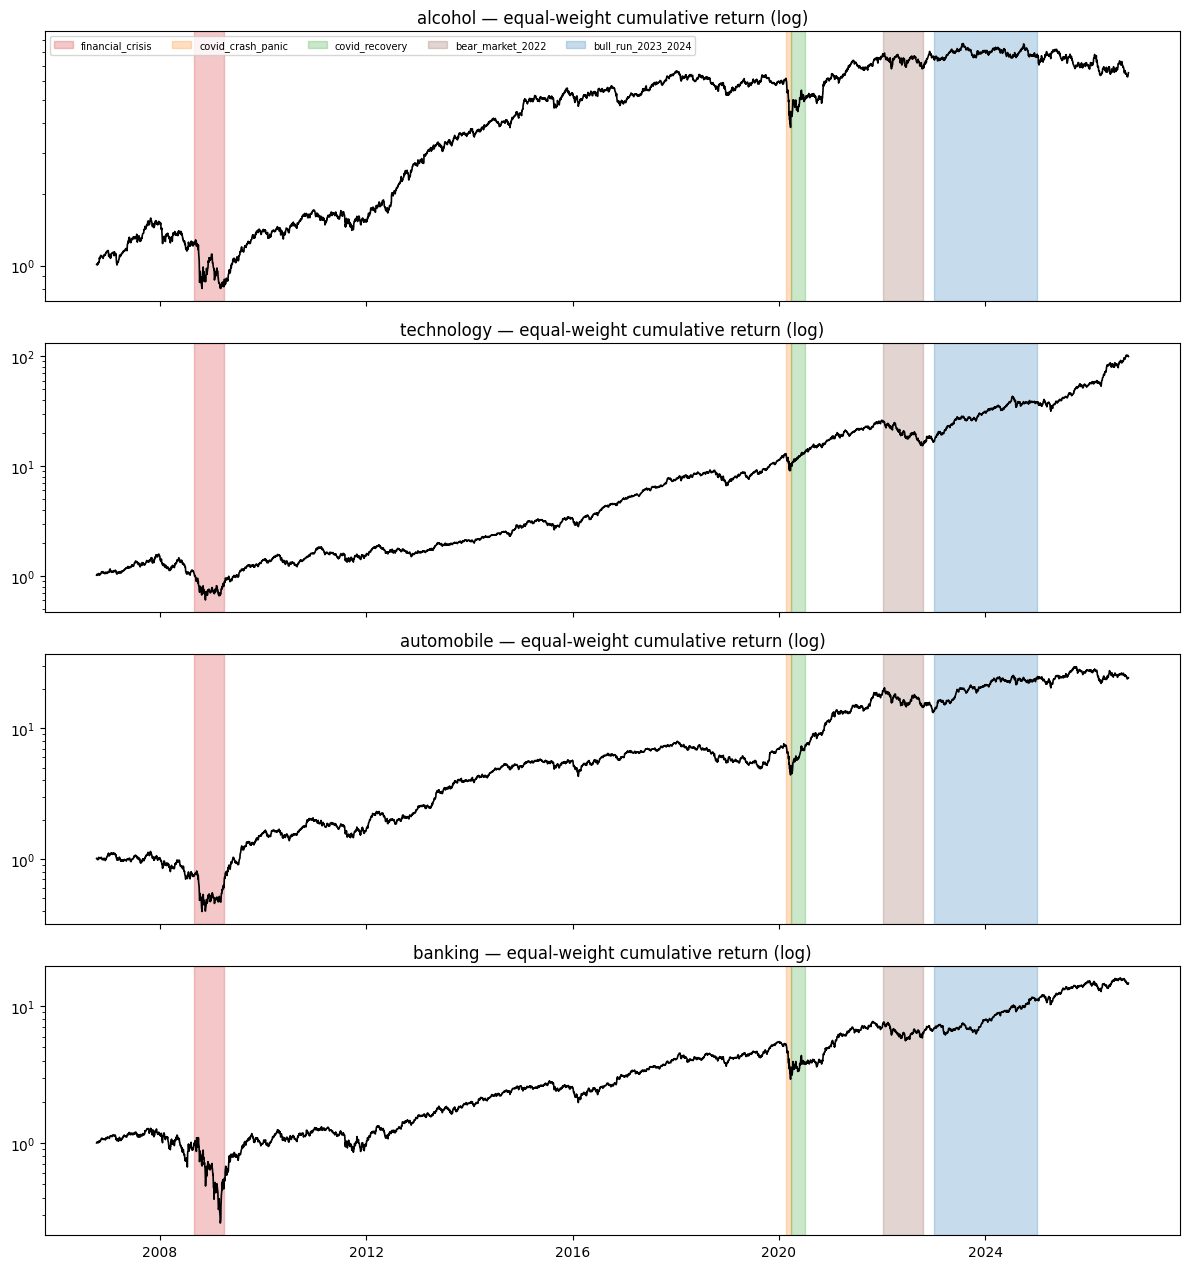

In [8]:
# ---------------- PLOT: equal-weight cumulative return with situations shaded ----------------
colors = {"financial_crisis": "#d62728", "covid_crash_panic": "#ff7f0e", "covid_recovery": "#2ca02c",
          "bear_market_2022": "#8c564b", "bull_run_2023_2024": "#1f77b4"}
fig, axes = plt.subplots(len(normal), 1, figsize=(12, 3.2 * len(normal)), sharex=True)
axes = np.atleast_1d(axes)
for ax, (industry, nd) in zip(axes, normal.items()):
    ew = nd.pivot_table(index="Date", columns="Ticker", values="Return").mean(axis=1)
    ax.plot((1 + ew).cumprod(), lw=1.2, color="black")
    ax.set_yscale("log"); ax.set_title(f"{industry} — equal-weight cumulative return (log)")
    for s, (a, b) in SITUATIONS.items():
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=colors[s], alpha=0.25, label=s)
axes[0].legend(ncol=5, fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()

In [9]:
# ---------------- OPTIONAL ZIP (created outside the dataset folder) ----------------
shutil.make_archive("dataset_bundle", "zip", DATASET_DIR)
print("Created dataset_bundle.zip")
try:
    from google.colab import files
    files.download("dataset_bundle.zip")
except Exception:
    pass

Created dataset_bundle.zip
